# 08 - اكتشاف الوجوه والعيون باستخدام Haar Cascade

**المشروع:** Vision Studio - معالجة الصور والرؤية بالحاسوب  
**المقرر:** معالجة الصور والرؤية بالحاسوب - بكالوريوس ذكاء اصطناعي  
**إشراف:** الدكتورة سمية الشيبة

يعتمد هذا الدفتر على **LAB 10 - Face and Eye Detection**، ويوسعه ليعمل على الصور والفيديوهات المحفوظة مع أدوات تفاعلية وحفظ النتائج، وكل ذلك دون إنترنت.

## أهداف الدفتر

1. تجهيز ملفات Haar Cascade وحفظها داخل المشروع.
2. اكتشاف الوجوه في الصور ورسم Bounding Boxes.
3. استخدام ROI للبحث عن العيون داخل كل وجه فقط.
4. فهم معاملات `scaleFactor` و`minNeighbors` و`minSize`.
5. مقارنة كاشفي العين العادي والنظارات.
6. إخفاء الوجوه باستخدام Blur أو Pixelation.
7. معالجة جميع الصور وحفظ النتائج وتقرير CSV.
8. اكتشاف الوجوه والعيون في الفيديو وحفظ MP4 الناتج.
9. تجهيز نفس الوظائف للنقل إلى OpenCV Android.

> خوارزمية Haar Cascade لا تحتاج إنترنت ولا GPU، وهي مناسبة لتوضيح مبادئ الكشف قبل الانتقال إلى YOLO.

## 1. استيراد المكتبات وربط Google Drive

In [1]:
# %pip uninstall -y \
#     opencv-python \
#     opencv-python-headless \
#     opencv-contrib-python \
#     opencv-contrib-python-headless

# %pip install -q --no-cache-dir --no-deps \
#     opencv-python-headless==4.10.0.84

In [2]:
from pathlib import Path
import csv
import shutil
import subprocess
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
    PROJECT_ROOT = Path(
        '/content/drive/MyDrive/'
        'VisionStudio_Android_ImageProcessing'
    )
except ImportError:
    IN_COLAB = False
    PROJECT_ROOT = Path('VisionStudio_Android_ImageProcessing')

IMAGE_INPUT_DIR = PROJECT_ROOT / '02_Data/Images/Input'
VIDEO_INPUT_DIR = PROJECT_ROOT / '02_Data/Videos/Input'
CASCADE_MODELS_DIR = PROJECT_ROOT / '03_Models/Haar_Cascades'
IMAGE_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Images/08_Face_Eye_Detection'
)
VIDEO_OUTPUT_DIR = (
    PROJECT_ROOT
    / '04_Outputs/Videos/08_Face_Eye_Detection'
)

for directory in [
    IMAGE_INPUT_DIR,
    VIDEO_INPUT_DIR,
    CASCADE_MODELS_DIR,
    IMAGE_OUTPUT_DIR,
    VIDEO_OUTPUT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print('Running in Colab:', IN_COLAB)
print('Image input:', IMAGE_INPUT_DIR)
print('Video input:', VIDEO_INPUT_DIR)
print('Cascade models:', CASCADE_MODELS_DIR)
print('Image output:', IMAGE_OUTPUT_DIR)
print('Video output:', VIDEO_OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Running in Colab: True
Image input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Video input: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Videos/Input
Cascade models: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/03_Models/Haar_Cascades
Image output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/08_Face_Eye_Detection
Video output: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Videos/08_Face_Eye_Detection


## 2. نسخ ملفات Haar Cascade إلى المشروع

In [4]:
CASCADE_FILE_NAMES = [
    'haarcascade_frontalface_default.xml',
    'haarcascade_eye.xml',
    'haarcascade_eye_tree_eyeglasses.xml'
]

opencv_cascade_directory = Path(cv2.data.haarcascades)

for cascade_name in CASCADE_FILE_NAMES:
    source_path = opencv_cascade_directory / cascade_name
    destination_path = CASCADE_MODELS_DIR / cascade_name

    if not source_path.exists():
        raise FileNotFoundError(
            f'ملف Haar غير موجود داخل OpenCV: {source_path}'
        )
    if not destination_path.exists():
        shutil.copy2(source_path, destination_path)
        print('Copied:', cascade_name)
    else:
        print('Already exists:', cascade_name)

FACE_MODEL_PATH = (
    CASCADE_MODELS_DIR
    / 'haarcascade_frontalface_default.xml'
)
EYE_MODEL_NAME = 'haarcascade_eye.xml'
EYE_MODEL_PATH = CASCADE_MODELS_DIR / EYE_MODEL_NAME

face_cascade = cv2.CascadeClassifier(str(FACE_MODEL_PATH))
eye_cascade = cv2.CascadeClassifier(str(EYE_MODEL_PATH))

if face_cascade.empty():
    raise RuntimeError('فشل تحميل نموذج اكتشاف الوجه.')
if eye_cascade.empty():
    raise RuntimeError('فشل تحميل نموذج اكتشاف العين.')

print('Face model loaded:', FACE_MODEL_PATH.name)
print('Eye model loaded:', EYE_MODEL_PATH.name)
print('Offline models are ready.')

Already exists: haarcascade_frontalface_default.xml
Already exists: haarcascade_eye.xml
Already exists: haarcascade_eye_tree_eyeglasses.xml
Face model loaded: haarcascade_frontalface_default.xml
Eye model loaded: haarcascade_eye.xml
Offline models are ready.


### لماذا نحفظ ملفات XML داخل المشروع؟

تأتي ملفات Haar مع OpenCV، لكن نسخها إلى `03_Models/Haar_Cascades` يضمن أن ملفات المشروع النهائية واضحة ويمكن تضمينها لاحقًا داخل مجلد `assets` في تطبيق Android دون تنزيل أي ملف من الإنترنت.

## 3. دوال العرض والمساعدة

In [5]:
def to_rgb(image):
    if image.ndim == 2:
        return image
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_comparison(results, columns=2, figure_width=14):
    items = list(results.items())
    rows = int(np.ceil(len(items) / columns))
    fig, axes = plt.subplots(
        rows, columns,
        figsize=(figure_width, rows * 4.8),
        squeeze=False
    )

    for axis, (title, result) in zip(axes.ravel(), items):
        axis.imshow(
            to_rgb(result),
            cmap='gray' if result.ndim == 2 else None
        )
        axis.set_title(title)
        axis.axis('off')

    for axis in axes.ravel()[len(items):]:
        axis.axis('off')

    plt.tight_layout()
    plt.show()


def resize_max_width(image, maximum_width=1000):
    if maximum_width is None or int(maximum_width) <= 0:
        return image
    height, width = image.shape[:2]
    if width <= int(maximum_width):
        return image
    scale = int(maximum_width) / width
    new_height = max(1, int(round(height * scale)))
    return cv2.resize(
        image, (int(maximum_width), new_height),
        interpolation=cv2.INTER_AREA
    )

## 4. دالة اكتشاف الوجه والعينين

In [6]:
def detect_faces_and_eyes(
    image,
    face_detector=face_cascade,
    eye_detector=eye_cascade,
    face_scale_factor=1.2,
    face_min_neighbors=5,
    minimum_face_size=30,
    eye_scale_factor=1.15,
    eye_min_neighbors=5,
    detect_eyes=True,
    equalize_histogram=True,
    maximum_eyes_per_face=2
):
    result = image.copy()
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    detection_gray = (
        cv2.equalizeHist(gray)
        if equalize_histogram else gray
    )

    minimum_face_size = max(20, int(minimum_face_size))
    faces = face_detector.detectMultiScale(
        detection_gray,
        scaleFactor=max(1.01, float(face_scale_factor)),
        minNeighbors=max(1, int(face_min_neighbors)),
        minSize=(minimum_face_size, minimum_face_size),
        flags=cv2.CASCADE_SCALE_IMAGE
    )

    detections = []
    total_eyes = 0

    for face_index, (x, y, width, height) in enumerate(faces, start=1):
        x, y, width, height = map(int, (x, y, width, height))
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (255, 0, 0), 3
        )
        cv2.putText(
            result, f'Face {face_index}',
            (x, max(22, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (255, 0, 0), 2, cv2.LINE_AA
        )

        eye_boxes = []
        if detect_eyes:
            # العيون توجد غالبًا في الجزء العلوي من الوجه.
            upper_height = max(1, int(height * 0.65))
            roi_gray = detection_gray[
                y:y + upper_height,
                x:x + width
            ]
            eyes = eye_detector.detectMultiScale(
                roi_gray,
                scaleFactor=max(1.01, float(eye_scale_factor)),
                minNeighbors=max(1, int(eye_min_neighbors)),
                minSize=(8, 8),
                flags=cv2.CASCADE_SCALE_IMAGE
            )

            sorted_eyes = sorted(
                eyes,
                key=lambda eye: int(eye[2]) * int(eye[3]),
                reverse=True
            )[:max(0, int(maximum_eyes_per_face))]

            for ex, ey, ew, eh in sorted_eyes:
                ex, ey, ew, eh = map(int, (ex, ey, ew, eh))
                absolute_box = (x + ex, y + ey, ew, eh)
                eye_boxes.append(absolute_box)
                cv2.rectangle(
                    result,
                    (x + ex, y + ey),
                    (x + ex + ew, y + ey + eh),
                    (0, 255, 0), 2
                )

        total_eyes += len(eye_boxes)
        detections.append({
            'face_box': (x, y, width, height),
            'eye_boxes': eye_boxes
        })

    return result, len(faces), total_eyes, detections, gray


def anonymize_faces(image, detections, method='blur'):
    result = image.copy()
    for detection in detections:
        x, y, width, height = detection['face_box']
        face_region = result[y:y + height, x:x + width]
        if face_region.size == 0:
            continue

        if method == 'pixelate':
            tiny_width = max(8, width // 14)
            tiny_height = max(8, height // 14)
            tiny = cv2.resize(
                face_region, (tiny_width, tiny_height),
                interpolation=cv2.INTER_LINEAR
            )
            anonymized = cv2.resize(
                tiny, (width, height),
                interpolation=cv2.INTER_NEAREST
            )
        else:
            kernel = max(15, min(width, height) // 3)
            if kernel % 2 == 0:
                kernel += 1
            anonymized = cv2.GaussianBlur(
                face_region, (kernel, kernel), 0
            )

        result[y:y + height, x:x + width] = anonymized
    return result

### شرح معاملات Haar المهمة

| المعامل | معناه | أثر زيادته |
|---|---|---|
| `scaleFactor` | مقدار تصغير الصورة في كل مرحلة بحث | يزيد السرعة وقد يفوّت بعض الوجوه |
| `minNeighbors` | عدد المستطيلات المتجاورة اللازمة لقبول الكشف | يقلل النتائج الخاطئة وقد يقلل عدد الوجوه |
| `minSize` | أصغر حجم وجه يُسمح باكتشافه | يتجاهل الوجوه الصغيرة |

القيم المناسبة ليست ثابتة لكل الصور. نبدأ عادة بـ `scaleFactor=1.2` و`minNeighbors=5` ثم نعدل حسب النتيجة.

## 5. قراءة الصور وإضافة صورة اختبار وجه محلية

In [17]:
UPLOAD_NEW_FILES = True
SUPPORTED_IMAGE_EXTENSIONS = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.tif', '.tiff', '.webp'
}


def load_images(directory):
    images = {}
    for path in sorted(directory.iterdir()):
        if (
            not path.is_file()
            or path.suffix.lower() not in SUPPORTED_IMAGE_EXTENSIONS
        ):
            continue
        image = cv2.imread(str(path), cv2.IMREAD_COLOR)
        if image is not None:
            images[path.name] = image
        else:
            print('تعذر قراءة:', path.name)
    return images


if IN_COLAB and UPLOAD_NEW_FILES:
    from google.colab import files

    uploaded = files.upload()
    for file_name, file_data in uploaded.items():
        image_array = np.frombuffer(file_data, dtype=np.uint8)
        image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)
        if image is None:
            print('تم تجاهل ملف غير صالح:', file_name)
            continue
        safe_name = Path(file_name).name
        cv2.imwrite(str(IMAGE_INPUT_DIR / safe_name), image)

# صورة Grace Hopper تأتي مع Matplotlib وتُستخدم للاختبار دون تنزيل.
sample_face_name = 'face_test_grace_hopper.jpg'
sample_face_path = IMAGE_INPUT_DIR / sample_face_name
if not sample_face_path.exists():
    try:
        from matplotlib.cbook import get_sample_data
        bundled_sample = Path(
            get_sample_data('grace_hopper.jpg', asfileobj=False)
        )
        shutil.copy2(bundled_sample, sample_face_path)
        print('تمت إضافة صورة اختبار وجه محلية:', sample_face_name)
    except Exception as error:
        print('تعذر إضافة صورة الاختبار المحلية:', error)

uploaded_images = load_images(IMAGE_INPUT_DIR)
if not uploaded_images:
    raise ValueError(
        'لا توجد صور. التقط صورة وجه في الدفتر 07 أو أضف صورة إلى مجلد الإدخال.'
    )

print(f'عدد الصور المتاحة: {len(uploaded_images)}')
for name, image in uploaded_images.items():
    height, width = image.shape[:2]
    print(f'- {name}: {width} x {height}')

Saving children.jpeg to children (1).jpeg
عدد الصور المتاحة: 9
- R.jpeg: 736 x 736
- balloons.jpg: 602 x 547
- camera_photo_20260917_225311.jpg: 640 x 480
- camera_photo_20260917_225540.jpg: 640 x 480
- camera_photo_20260917_232608.jpg: 640 x 480
- children (1).jpeg: 1376 x 774
- children.jpeg: 1376 x 774
- coins.jpg: 400 x 390
- face_test_grace_hopper.jpg: 512 x 600


## 6. اختيار صورة الكشف

Selected image: children.jpeg
Shape: (562, 1000, 3)


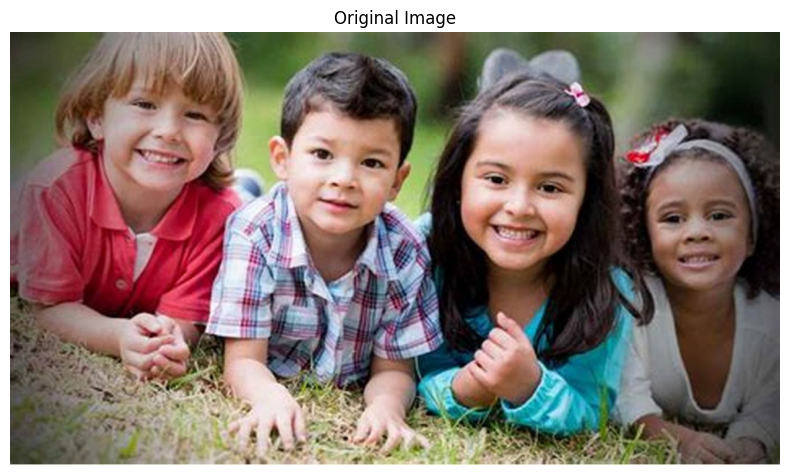

In [18]:
# اكتب اسم صورة الكاميرا هنا، أو اتركه فارغًا لاختيار صورة الاختبار.
SELECTED_IMAGE_NAME = 'children.jpeg'

if SELECTED_IMAGE_NAME:
    if SELECTED_IMAGE_NAME not in uploaded_images:
        available = ', '.join(uploaded_images.keys())
        raise ValueError(
            f'الصورة غير موجودة. الصور المتاحة: {available}'
        )
    selected_name = SELECTED_IMAGE_NAME
elif sample_face_name in uploaded_images:
    selected_name = sample_face_name
else:
    selected_name = next(iter(uploaded_images))

selected_image = resize_max_width(
    uploaded_images[selected_name], 1000
)

print('Selected image:', selected_name)
print('Shape:', selected_image.shape)
show_comparison({'Original Image': selected_image}, columns=1, figure_width=8)

## 7. تنفيذ اكتشاف الوجه والعينين

Faces detected: 3
Eyes detected: 6


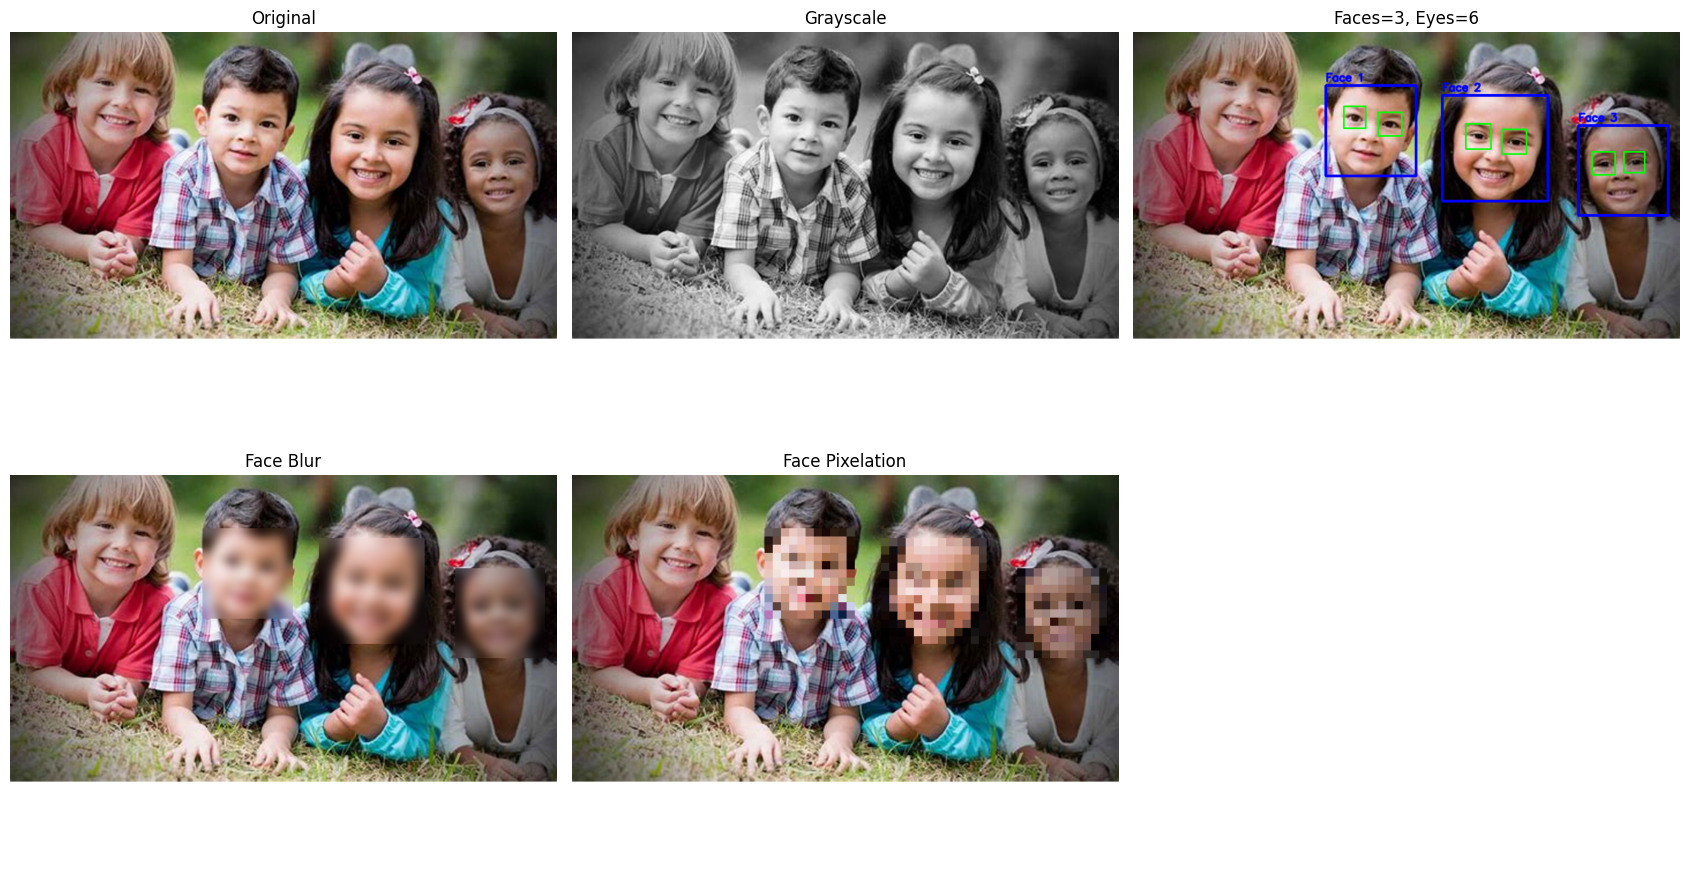

In [21]:
annotated_image, face_count, eye_count, detections, gray_image = (
    detect_faces_and_eyes(
        selected_image,
        face_scale_factor=1.2,
        face_min_neighbors=5,
        minimum_face_size=30,
        eye_scale_factor=1.15,
        eye_min_neighbors=5
    )
)
blurred_faces = anonymize_faces(
    selected_image, detections, method='blur'
)
pixelated_faces = anonymize_faces(
    selected_image, detections, method='pixelate'
)

print('Faces detected:', face_count)
print('Eyes detected:', eye_count)

show_comparison(
    {
        'Original': selected_image,
        'Grayscale': gray_image,
        f'Faces={face_count}, Eyes={eye_count}': annotated_image,
        'Face Blur': blurred_faces,
        'Face Pixelation': pixelated_faces
    },
    columns=3,
    figure_width=17
)

## 8. لماذا نبحث عن العين داخل ROI الوجه؟

بعد اكتشاف الوجه نأخذ من الصورة:

```python
roi_gray = gray[y:y+h, x:x+w]
```

ثم نبحث عن العين داخل هذه المنطقة فقط. هذا يقلل مساحة البحث ويرفع السرعة ويقلل اكتشاف أشياء خارج الوجه على أنها عيون. وفي هذا الدفتر قُيّد البحث بالجزء العلوي من الوجه لأن العينين لا تكونان عادة في الجزء السفلي.

## 9. أداة تفاعلية لضبط معاملات الكشف

In [22]:
try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('الأدوات التفاعلية متاحة تلقائيًا داخل Google Colab.')


def interactive_face_detection(
    scale_factor=1.2,
    min_neighbors=5,
    minimum_face_size=30,
    eye_min_neighbors=5,
    detect_eyes=True,
    equalize_histogram=True
):
    result, faces, eyes, _, _ = detect_faces_and_eyes(
        selected_image,
        face_scale_factor=scale_factor,
        face_min_neighbors=min_neighbors,
        minimum_face_size=minimum_face_size,
        eye_min_neighbors=eye_min_neighbors,
        detect_eyes=detect_eyes,
        equalize_histogram=equalize_histogram
    )
    show_comparison(
        {
            'Original': selected_image,
            f'Faces={faces}, Eyes={eyes}': result
        },
        columns=2,
        figure_width=12
    )


if WIDGETS_AVAILABLE:
    face_controls = widgets.interactive(
        interactive_face_detection,
        scale_factor=widgets.FloatSlider(
            value=1.2, min=1.05, max=1.5, step=0.05,
            description='Scale'
        ),
        min_neighbors=widgets.IntSlider(
            value=5, min=1, max=12, step=1,
            description='Neighbors'
        ),
        minimum_face_size=widgets.IntSlider(
            value=30, min=20, max=200, step=10,
            description='Min size'
        ),
        eye_min_neighbors=widgets.IntSlider(
            value=5, min=1, max=12, step=1,
            description='Eye N'
        ),
        detect_eyes=widgets.Checkbox(
            value=True, description='Detect eyes'
        ),
        equalize_histogram=widgets.Checkbox(
            value=True, description='Equalize'
        )
    )
    display(face_controls)
else:
    interactive_face_detection()

interactive(children=(FloatSlider(value=1.2, description='Scale', max=1.5, min=1.05, step=0.05), IntSlider(val…

## 10. مقارنة نموذج العين العادي ونموذج النظارات

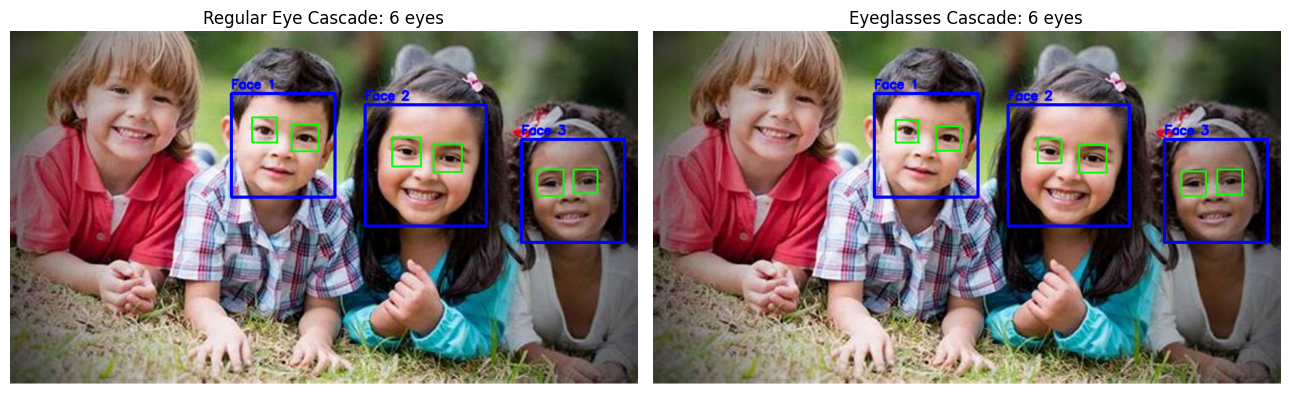

In [23]:
regular_eye_detector = cv2.CascadeClassifier(
    str(CASCADE_MODELS_DIR / 'haarcascade_eye.xml')
)
glasses_eye_detector = cv2.CascadeClassifier(
    str(CASCADE_MODELS_DIR / 'haarcascade_eye_tree_eyeglasses.xml')
)

regular_result, regular_faces, regular_eyes, _, _ = (
    detect_faces_and_eyes(
        selected_image,
        eye_detector=regular_eye_detector
    )
)
glasses_result, glasses_faces, glasses_eyes, _, _ = (
    detect_faces_and_eyes(
        selected_image,
        eye_detector=glasses_eye_detector
    )
)

show_comparison(
    {
        f'Regular Eye Cascade: {regular_eyes} eyes': regular_result,
        f'Eyeglasses Cascade: {glasses_eyes} eyes': glasses_result
    },
    columns=2,
    figure_width=13
)

## 11. معالجة جميع الصور وحفظ النتائج

In [24]:
image_report = []
saved_image_files = []

for file_name, source_image in uploaded_images.items():
    source_image = resize_max_width(source_image, 1400)
    annotated, faces, eyes, source_detections, source_gray = (
        detect_faces_and_eyes(source_image)
    )
    anonymized = anonymize_faces(
        source_image, source_detections, method='blur'
    )

    stem = Path(file_name).stem
    image_directory = IMAGE_OUTPUT_DIR / stem
    image_directory.mkdir(parents=True, exist_ok=True)

    results = {
        '00_original.png': source_image,
        '01_grayscale.png': source_gray,
        '02_faces_eyes.png': annotated,
        '03_faces_blurred.png': anonymized
    }

    for output_name, result in results.items():
        output_path = image_directory / output_name
        if not cv2.imwrite(str(output_path), result):
            raise IOError(f'فشل حفظ الصورة: {output_path}')
        saved_image_files.append(output_path)

    for face_index, detection in enumerate(source_detections, start=1):
        x, y, width, height = detection['face_box']
        face_crop = source_image[y:y + height, x:x + width]
        crop_path = image_directory / f'face_{face_index:02d}.png'
        if face_crop.size > 0 and cv2.imwrite(str(crop_path), face_crop):
            saved_image_files.append(crop_path)

    image_report.append({
        'file_name': file_name,
        'faces': faces,
        'eyes': eyes
    })

report_path = IMAGE_OUTPUT_DIR / 'face_eye_detection_report.csv'
with report_path.open('w', newline='', encoding='utf-8-sig') as report_file:
    writer = csv.DictWriter(
        report_file,
        fieldnames=['file_name', 'faces', 'eyes']
    )
    writer.writeheader()
    writer.writerows(image_report)

print(f'تمت معالجة {len(uploaded_images)} صورة.')
print(f'تم حفظ {len(saved_image_files)} ملف صورة.')
print('CSV report:', report_path)
for row in image_report:
    print(
        f"- {row['file_name']}: "
        f"faces={row['faces']}, eyes={row['eyes']}"
    )

تمت معالجة 9 صورة.
تم حفظ 47 ملف صورة.
CSV report: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/08_Face_Eye_Detection/face_eye_detection_report.csv
- R.jpeg: faces=1, eyes=2
- balloons.jpg: faces=0, eyes=0
- camera_photo_20260917_225311.jpg: faces=1, eyes=2
- camera_photo_20260917_225540.jpg: faces=1, eyes=2
- camera_photo_20260917_232608.jpg: faces=1, eyes=2
- children (1).jpeg: faces=3, eyes=6
- children.jpeg: faces=3, eyes=6
- coins.jpg: faces=0, eyes=0
- face_test_grace_hopper.jpg: faces=1, eyes=1


## 12. اكتشاف الوجوه والعيون في الفيديو

اترك `PROCESS_VIDEO = False` أثناء تشغيل الدفتر لأول مرة. لمعالجة فيديو صالح موجود في `02_Data/Videos/Input` غيّره إلى `True`، ثم اختر اسم الفيديو أو اترك الاسم فارغًا لاختيار أول فيديو صالح.

يمكن استخدام `DETECT_EVERY_N_FRAMES = 2` لزيادة السرعة؛ سيعاد استخدام آخر كشف في الإطار التالي.

In [25]:
SUPPORTED_VIDEO_EXTENSIONS = {
    '.mp4', '.avi', '.mov', '.mkv', '.webm', '.m4v'
}


def valid_video_paths(directory):
    valid_paths = []
    for path in sorted(directory.iterdir()):
        if (
            not path.is_file()
            or path.suffix.lower() not in SUPPORTED_VIDEO_EXTENSIONS
        ):
            continue
        capture = cv2.VideoCapture(str(path))
        success, frame = capture.read()
        capture.release()
        if success and frame is not None:
            valid_paths.append(path)
        else:
            print('تم تجاهل فيديو غير صالح:', path.name)
    return valid_paths


def draw_detections(image, detections):
    result = image.copy()
    for face_index, detection in enumerate(detections, start=1):
        x, y, width, height = detection['face_box']
        cv2.rectangle(
            result, (x, y), (x + width, y + height),
            (255, 0, 0), 3
        )
        cv2.putText(
            result, f'Face {face_index}',
            (x, max(22, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (255, 0, 0), 2, cv2.LINE_AA
        )
        for ex, ey, ew, eh in detection['eye_boxes']:
            cv2.rectangle(
                result, (ex, ey), (ex + ew, ey + eh),
                (0, 255, 0), 2
            )
    return result


def process_face_video(
    input_path,
    output_path,
    maximum_width=640,
    maximum_seconds=None,
    detect_every_n_frames=1
):
    capture = cv2.VideoCapture(str(input_path))
    if not capture.isOpened():
        raise ValueError(f'تعذر فتح الفيديو: {input_path}')

    fps = float(capture.get(cv2.CAP_PROP_FPS))
    if fps <= 0:
        fps = 25.0
    total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    maximum_frames = None
    if maximum_seconds is not None and float(maximum_seconds) > 0:
        maximum_frames = int(float(maximum_seconds) * fps)

    success, frame = capture.read()
    if not success or frame is None:
        capture.release()
        raise ValueError('لا يحتوي الفيديو على إطار صالح.')

    frame = resize_max_width(frame, maximum_width)
    frame_height, frame_width = frame.shape[:2]
    even_width = frame_width - frame_width % 2
    even_height = frame_height - frame_height % 2
    frame = frame[:even_height, :even_width]

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*'mp4v'),
        fps,
        (even_width, even_height)
    )
    if not writer.isOpened():
        capture.release()
        raise RuntimeError('تعذر إنشاء فيديو النتيجة.')

    frame_index = 0
    latest_detections = []
    total_face_detections = 0
    start_time = time.perf_counter()

    while success and frame is not None:
        if maximum_frames is not None and frame_index >= maximum_frames:
            break

        frame = resize_max_width(frame, maximum_width)
        frame = frame[:even_height, :even_width]

        if frame_index % max(1, int(detect_every_n_frames)) == 0:
            _, faces, _, latest_detections, _ = detect_faces_and_eyes(
                frame
            )
            total_face_detections += faces

        annotated_frame = draw_detections(frame, latest_detections)
        writer.write(annotated_frame)
        frame_index += 1

        if frame_index % 30 == 0:
            if total_frames > 0:
                progress = min(100, 100 * frame_index / total_frames)
                print(
                    f'Processed {frame_index}/{total_frames} '
                    f'frames ({progress:.1f}%)'
                )
            else:
                print('Processed frames:', frame_index)

        success, frame = capture.read()

    capture.release()
    writer.release()

    elapsed = time.perf_counter() - start_time
    speed = frame_index / elapsed if elapsed > 0 else 0.0
    return {
        'frames': frame_index,
        'elapsed_seconds': elapsed,
        'processing_fps': speed,
        'face_detections': total_face_detections
    }


def finalize_video(silent_path, original_path, final_path):
    ffmpeg_path = shutil.which('ffmpeg')
    if ffmpeg_path is None:
        shutil.copy2(silent_path, final_path)
        return False

    command = [
        ffmpeg_path, '-y',
        '-i', str(silent_path),
        '-i', str(original_path),
        '-map', '0:v:0', '-map', '1:a?',
        '-c:v', 'libx264', '-preset', 'fast', '-crf', '23',
        '-pix_fmt', 'yuv420p',
        '-c:a', 'aac', '-b:a', '128k',
        '-shortest', '-movflags', '+faststart',
        str(final_path)
    ]
    try:
        subprocess.run(
            command, check=True,
            stdout=subprocess.PIPE, stderr=subprocess.PIPE
        )
        return True
    except subprocess.CalledProcessError:
        shutil.copy2(silent_path, final_path)
        return False

In [26]:
PROCESS_VIDEO = False
SELECTED_VIDEO_NAME = ''
MAX_VIDEO_SECONDS = 20
VIDEO_OUTPUT_WIDTH = 640
DETECT_EVERY_N_FRAMES = 1

available_videos = valid_video_paths(VIDEO_INPUT_DIR)

if PROCESS_VIDEO:
    if not available_videos:
        raise ValueError(
            'لا يوجد فيديو صالح. أضف MP4 إلى مجلد Videos/Input.'
        )

    video_by_name = {path.name: path for path in available_videos}
    if SELECTED_VIDEO_NAME:
        if SELECTED_VIDEO_NAME not in video_by_name:
            raise ValueError('اسم الفيديو المحدد غير موجود.')
        selected_video_path = video_by_name[SELECTED_VIDEO_NAME]
    else:
        selected_video_path = available_videos[0]

    temporary_output = (
        VIDEO_OUTPUT_DIR
        / f'{selected_video_path.stem}_faces_eyes_opencv.mp4'
    )
    final_output = (
        VIDEO_OUTPUT_DIR
        / f'{selected_video_path.stem}_faces_eyes.mp4'
    )

    video_statistics = process_face_video(
        selected_video_path,
        temporary_output,
        maximum_width=VIDEO_OUTPUT_WIDTH,
        maximum_seconds=MAX_VIDEO_SECONDS,
        detect_every_n_frames=DETECT_EVERY_N_FRAMES
    )
    converted = finalize_video(
        temporary_output, selected_video_path, final_output
    )

    print('Input video:', selected_video_path)
    print('Output video:', final_output)
    print('Browser-compatible conversion:', converted)
    print('Frames:', video_statistics['frames'])
    print(
        'Processing FPS:',
        f"{video_statistics['processing_fps']:.2f}"
    )
    print(
        'Total face detections:',
        video_statistics['face_detections']
    )
else:
    print('معالجة الفيديو معطلة. غيّر PROCESS_VIDEO إلى True عند الحاجة.')
    print('Valid videos found:', len(available_videos))

معالجة الفيديو معطلة. غيّر PROCESS_VIDEO إلى True عند الحاجة.
Valid videos found: 3


## 13. تطبيق الكشف على صورة الكاميرا

لا تحتاج إلى فتح الكاميرا من جديد هنا. الصورة التي التقطتها في الدفتر 07 محفوظة داخل `02_Data/Images/Input`، ولذلك ستظهر تلقائيًا ضمن `uploaded_images`.

ضع اسمها في:

```python
SELECTED_IMAGE_NAME = 'camera_photo_YYYYMMDD_HHMMSS.jpg'
```

ثم أعد تنفيذ خلايا اختيار الصورة والكشف. بهذه الطريقة لا نكرر مشاكل اتصال كاميرا Colab، بينما يعمل الكشف الحقيقي المباشر لاحقًا داخل تطبيق Android.

## 14. القيود العملية لـ Haar Cascade

- يعمل أفضل مع الوجه الأمامي والإضاءة الجيدة.
- قد يفشل مع دوران الوجه الكبير أو الإضاءة الضعيفة.
- قد يعطي مستطيلات خاطئة في الخلفيات المعقدة.
- لا يتعرف على هوية الشخص؛ هو يحدد وجود وجه فقط.
- `minNeighbors` الصغير يزيد الحساسية والنتائج الخاطئة.
- YOLO أو نماذج كشف الوجه الحديثة أدق، لكنها أكبر وأكثر استهلاكًا للموارد.

## 15. الربط بتطبيق Android

| Python/Colab | OpenCV Android | الاستخدام |
|---|---|---|
| `cv2.CascadeClassifier` | `CascadeClassifier` | تحميل ملفات XML |
| `detectMultiScale` | `detectMultiScale` | اكتشاف الوجوه والعيون |
| ROI slicing | `Mat.submat` | البحث عن العين داخل الوجه |
| `cv2.rectangle` | `Imgproc.rectangle` | رسم المستطيلات |
| `GaussianBlur` | `Imgproc.GaussianBlur` | إخفاء الوجه |

سنضع ملفات XML داخل `app/src/main/assets/haarcascades/`، ثم ننسخها عند أول تشغيل إلى مساحة التطبيق ونحمّلها. وسيأخذ CameraX كل إطار، يحوله إلى `Mat`، يطبق الكشف، ثم يعرض النتيجة دون إنترنت.

## 16. أسئلة للمناقشة والتقرير

1. لماذا نحول الصورة إلى Grayscale قبل Haar Cascade؟
2. ما فائدة `equalizeHist` قبل الكشف؟
3. لماذا نبحث عن العين داخل ROI الوجه؟
4. ماذا يحدث عند جعل `minNeighbors=1`؟
5. ما أثر زيادة `scaleFactor` على السرعة والدقة؟
6. ما الفرق بين اكتشاف الوجه والتعرف على هوية الشخص؟
7. لماذا نحتاج نموذجًا مختلفًا للعين والنظارات؟
8. ما الفرق بين Haar Cascade وYOLO؟

> بعد التأكد من حفظ النتائج استخدم `Edit → Clear all outputs` لتقليل حجم الدفتر.

**الخطوة التالية:** الدفتر `09_YOLO_Offline_Object_Detection.ipynb` لاكتشاف الأجسام دلاليًا في الصور والفيديو.